# Reading the OFF (Object File Format) with `pyramids-mesh`

The **OFF** (Object File Format) is a minimal polygon-mesh format: a line `OFF`, then an `nvert nface nedge` count, the vertex coordinates, and one line per face giving its vertex count and indices (optionally trailed by an RGBA colour). The sample here is a cube — **eight vertices, six quadrilateral faces** — complete with inline `#` comments and per-face colours, both of which the reader tolerates. This notebook reads it into a `pyramids.netcdf.ugrid` object and explores the quirks that come with a 3D surface flattened into a 2D mesh model.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pathlib import Path

import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
MESH = DATA / "off" / "comments.off"
MESH.name, MESH.exists()
import matplotlib.pyplot as plt

The OFF file lives in the `off/` sub-folder (see its `SOURCE.txt`), so we build the path as `DATA / "off" / "comments.off"`. The tuple confirms it resolves.

## 3. Read the file in one call

Reading emits two warnings worth understanding: the reader **reverses clockwise faces to counter-clockwise** (a consistent winding a writer can round-trip) and flags **degenerate faces** that have no planar winding. Both are expected when a 3D cube's faces are projected onto the 2D plane — vertical faces collapse.

In [2]:
ds = UgridDataset.read_file(MESH, driver="off")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 4 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=8, n_face=6, n_edge=0, variables=['node_z'])

In [3]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

Despite the warnings the read succeeds: a `UgridDataset` with the cube's eight nodes and six faces. The warnings are diagnostics, not errors.

## 4. Explore the dataset

A handful of attributes describe what we loaded: node and face counts, the coordinate reference system, the names of any data variables, and the spatial extent.

In [4]:
import pandas as pd
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "data_variable_names": ds.data_variable_names,
    "bounds": ds.bounds,
}).to_frame("value")

,value
n_node,8
n_face,6
crs,None
epsg,None
data_variable_names,[node_z]
bounds,"(-1.632993, -1.632993, 1.632993, 1.632993)"


**8 nodes, 6 faces.** `crs`/`epsg` are `None` — OFF is a pure geometry format with no georeferencing. A `node_z` variable holds the vertices' third coordinate. The `bounds` are symmetric about the origin, as befits a centred cube.

## 5. A statistical summary of the fields

`summary()` returns a pandas frame with one row per data variable (count, min, max, mean, std).

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,8,-1.154701,1.154701,0.0,1.154701


The `node_z` row captures the cube's vertex heights. There is no per-face field until we attach one.

## 6. The underlying `Mesh2d` geometry

`ds.mesh` is the `Mesh2d` object carrying the raw topology: node coordinates, the face-node connectivity table of shape `(n_face, k)` (row *i* lists the node indices of cell *i*), per-face areas, and cell centroids.

In [6]:
mesh = ds.mesh
fnc = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
centroids = np.asarray(mesh.face_centroids)  # shape (2, n_face)
pd.Series({
    "connectivity_shape": fnc.shape,
    "nodes_per_face_k": fnc.shape[1],
    "area_min": float(areas.min()),
    "area_max": float(areas.max()),
    "centroids_shape": centroids.shape,
    "mesh_bounds": mesh.bounds,
}).to_frame("value")

,value
connectivity_shape,"(6, 4)"
nodes_per_face_k,4
area_min,0.0
area_max,5.333332
centroids_shape,"(2, 6)"
mesh_bounds,"(-1.632993, -1.632993, 1.632993, 1.632993)"


`k = 4` — these are **quadrilateral** faces, not triangles (the key difference from the surface formats in the sibling notebooks). The area range spans from a genuine quad face down to **0.0**: the cube's vertical faces project to zero planar area, which is exactly the 'degenerate face' the reader warned about.

## 7. The mesh outline (wireframe)

`plot_outline()` draws the bare cell edges, with no field attached — the quickest look at the raw geometry this driver produced.

Text(0.5, 1.0, 'OFF mesh outline')

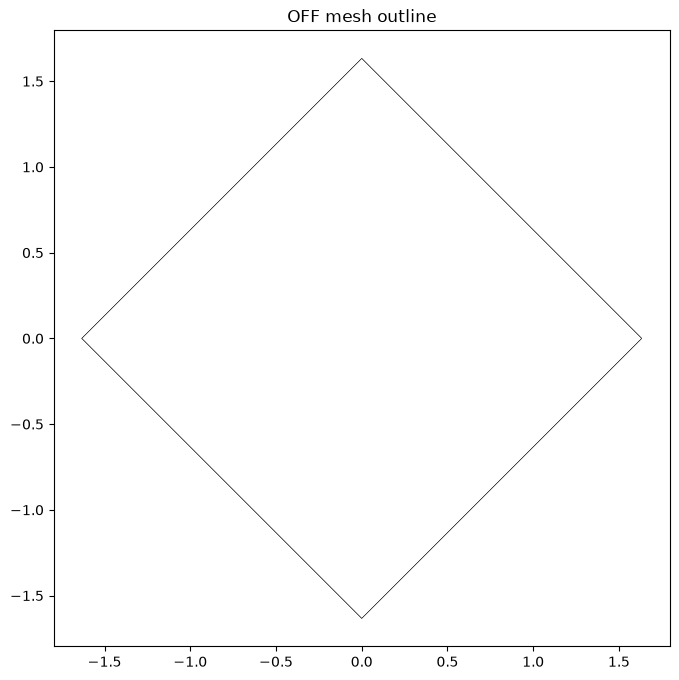

In [7]:
g = ds.plot_outline()
g.ax.set_title("OFF mesh outline")


The outline is the cube's six quad faces seen in plan view — several overlap because a 3D box flattened to the XY plane folds its top, bottom and side faces on top of one another.

## 8. A data map: attach and colour by cell area

These surface formats carry no field data, so there is nothing to colour by yet. We attach a derived **`cell_area`** variable at the face location and plot it — turning the geometry into a proper choropleth.

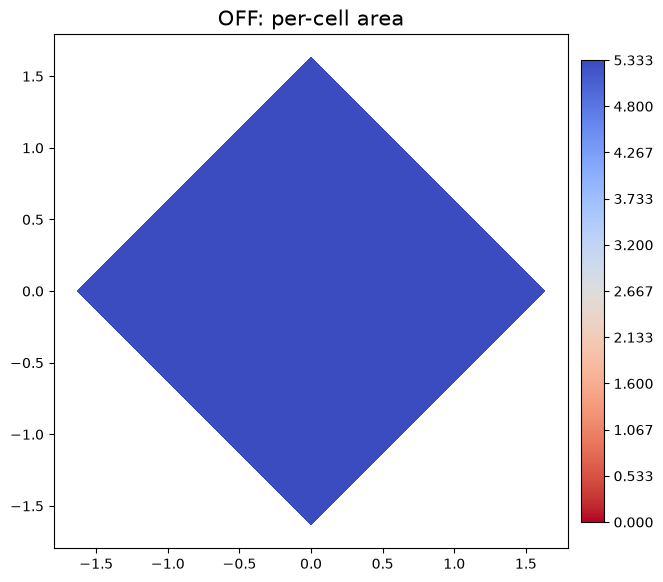

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True,
        title="OFF: per-cell area")


Colouring by `cell_area` makes the projection explicit: the one face parallel to the plane shows a real area while the vertical faces render as zero-area slivers. This is the honest picture of a 3D surface living in a 2D mesh model.

## 9. GIS operations, for free

Because a `UgridDataset` is a first-class pyramids object, a whole GIS toolkit comes along. First, every face as a row in a GeoDataFrame.

In [9]:
gdf = ds.to_geodataframe()
print(gdf.shape, list(gdf.columns))
gdf.head()

(6, 1) ['geometry']


,geometry
0,"POLYGON ((1.63299 0, 0 1.63299, -1.63299 0, 0 ..."
1,"POLYGON ((0 -1.63299, 1.63299 0, 1.63299 0, 0 ..."
2,"POLYGON ((1.63299 0, 0 1.63299, 0 1.63299, 1.6..."
3,"POLYGON ((0 1.63299, -1.63299 0, -1.63299 0, 0..."
4,"POLYGON ((0 -1.63299, -1.63299 0, -1.63299 0, ..."


Six polygon rows, one per quad face. Some are degenerate (collinear) polygons — the 2D shadow of the cube's vertical sides.

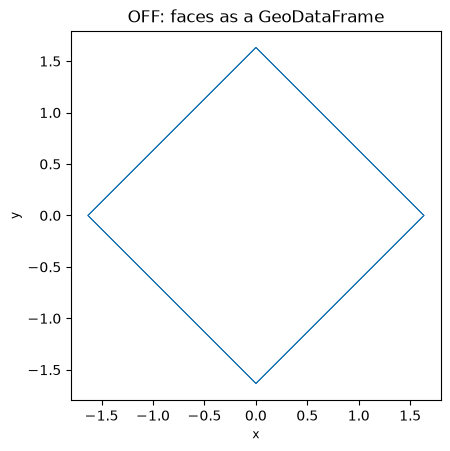

In [10]:
ax = gdf.boundary.plot(color="#1f77b4", linewidth=0.6)
ax.set_title("OFF: faces as a GeoDataFrame")
ax.set_aspect("equal")


The GeoDataFrame is the gateway to the entire shapely/geopandas ecosystem — spatial joins, buffering, reprojection, export to any OGR vector format — all on the mesh cells.

### Bounding polygon

`bounding_polygon()` returns a single shapely geometry: the dissolved outer footprint of the mesh.

Polygon 5.3333


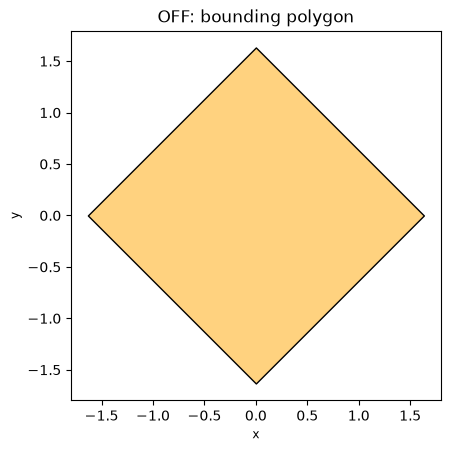

In [11]:
import geopandas as gpd

poly = ds.bounding_polygon()
ax = gpd.GeoSeries([poly]).plot(facecolor="#ffd27f", edgecolor="k")
ax.set_title("OFF: bounding polygon")
ax.set_aspect("equal")
print(type(poly).__name__, round(poly.area, 4))

The bounding polygon is the outer silhouette of the projected cube — the diamond its eight vertices trace in plan view.

### Derived topology and connectivity

A few more derived quantities are a method call away. `circumcenters()` is defined only for triangular meshes; `exterior_edges()` indexes the boundary edges; `connected_components()` labels disjoint pieces; `sparse_adjacency()` is the face-to-face graph as a sparse matrix.

In [12]:
try:
    cc = np.asarray(ds.circumcenters())
    circ = f"{cc.shape} array"
except ValueError as e:
    circ = f"skipped ({e})"
ext = np.asarray(ds.exterior_edges())
comp = np.asarray(ds.connected_components())
adj = ds.sparse_adjacency()
pd.Series({
    "circumcenters": circ,
    "n_boundary_edges": int(ext.size),
    "n_connected_components": int(np.unique(comp).size),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}).to_frame("value")

,value
circumcenters,skipped (circumcenters is only defined for tri...
n_boundary_edges,0
n_connected_components,1
adjacency_shape,"(6, 6)"
adjacency_nnz,24


**`circumcenters()` is skipped here** — it is defined only for triangular meshes, and this is a quad mesh, so the call raises a `ValueError` that we catch and report. Boundary-edge, connected-component and adjacency queries all still work regardless of face shape.

### Cropping to a bounding box

`crop(bbox=...)` keeps the faces that fall within (or touch) a rectangle, returning a new `UgridDataset`. Here we crop to the left portion of the extent and redraw it.

faces: 6 -> 4


Text(0.5, 1.0, 'OFF: cropped to left 60%')

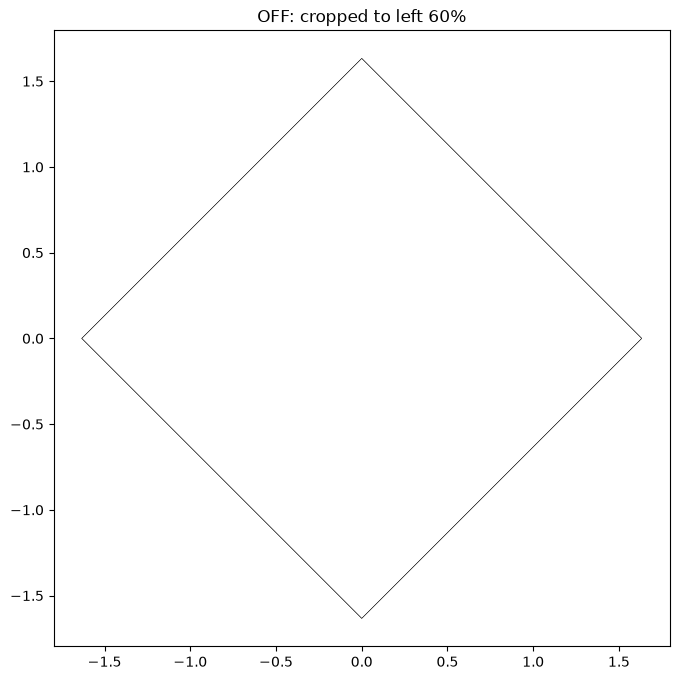

In [13]:
xmin, ymin, xmax, ymax = ds.bounds
bbox = (xmin, ymin, xmin + 0.6 * (xmax - xmin), ymax)
cropped = ds.crop(bbox=bbox)
print(f"faces: {ds.n_face} -> {cropped.n_face}")
gc = cropped.plot_outline()
gc.ax.set_title("OFF: cropped to left 60%")


Cropping to the left 60% of the extent keeps the quad faces touching the box — a smaller `UgridDataset` carved from the cube's footprint.

### Round-tripping and the xarray view

`to_file(..., driver=...)` writes the mesh back out in any writable driver (here the solver-neutral 2DM), and `to_xarray()` exposes the whole dataset as an `xarray.Dataset` for NetCDF-style analysis.

In [14]:
import tempfile

out = Path(tempfile.gettempdir()) / "roundtrip.2dm"
ds.to_file(out, driver="2dm")
xds = ds.to_xarray()
print("wrote", out.name, "bytes:", out.stat().st_size)
print(xds.dims)

wrote roundtrip.2dm bytes: 342
FrozenMappingWarningOnValuesAccess({'mesh2d_scalar': 1, 'mesh2d_nNodes': 8, 'mesh2d_nFaces': 6, 'mesh2d_nMaxFaceNodes': 4})


The mesh survives the round-trip to a different format, and `to_xarray()` hands us a familiar labelled-array object — proof that a format-specific reader produces a fully generic, interoperable dataset.

## 10. What we skip here, and why

- **`to_crs(...)`** needs a source CRS to reproject from, but OFF files carry no georeferencing (`crs=None`), so there is nothing to reproject. Attach a CRS first if the coordinates are known to be in a specific projection.
- **`rasterize_like(...)` / `regrid(...)`** require a *reference grid* (a raster or target mesh) to sample onto; with only this standalone mesh in hand there is no target, so they are out of scope for this tutorial.

## Takeaway

OFF exercises two things the triangular surface formats do not: **non-triangular (quad) faces** and the **winding/degeneracy normalisation** a 3D-surface-in-2D triggers. The reader parses, normalises winding, and warns about degenerate faces, then hands back an ordinary `UgridDataset`. Triangle-only operations like `circumcenters` bow out cleanly on a quad mesh, while the rest of the pyramids toolkit works unchanged.